In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetic_data.csv", na_values="?", low_memory=False)
print(df.shape)
df.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [4]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [6]:
df["target"] = (df["readmitted"] == "<30").astype(int)
print(df["target"].value_counts())
print("Positive rate:", df["target"].mean())

target
0    90409
1    11357
Name: count, dtype: int64
Positive rate: 0.11159915885462728


In [7]:
before = len(df)
df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]
print("Removed:", before - len(df), "| Remaining:", len(df))
print("Positive rate:", df["target"].mean())

Removed: 2423 | Remaining: 99343
Positive rate: 0.11388824577474005


In [8]:
df = df.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")
print("Rows:", len(df))
print("Positive rate:", df["target"].mean())
print("Unique patients:", df["patient_nbr"].nunique())

Rows: 69990
Positive rate: 0.08979854264894985
Unique patients: 69990


In [10]:
todrop = ["weight", "max_glu_serum", "A1Cresult", "payer_code", "medical_specialty", "encounter_id", "patient_nbr", "readmitted"]
df = df.drop(columns=todrop)
print(df.shape)
missing = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing.head(8))

(69990, 43)
race                   2.741820
diag_3                 1.748821
diag_2                 0.418631
diag_1                 0.014288
admission_type_id      0.000000
admission_source_id    0.000000
time_in_hospital       0.000000
num_lab_procedures     0.000000
dtype: float64


In [ ]:
def group_diag(code):
    if pd.isna(code):
        return "Unknown"
    if str(code).startswith(("E", "V")):
        return "Other"
    c = float(code)
    if 390 <= c <= 459 or c == 785: return "Circulatory"
    if 460 <= c <= 519 or c == 786: return "Respiratory"
    if 520 <= c <= 579 or c == 787: return "Digestive"
    if int(c) == 250:               return "Diabetes"
    if 800 <= c <= 999:             return "Injury"
    if 710 <= c <= 739:             return "Musculoskeletal"
    if 580 <= c <= 629 or c == 788: return "Genitourinary"
    if 140 <= c <= 239:             return "Neoplasms"
    return "Other"

df["diag_group"] = df["diag_1"].apply(group_diag)
df = df.drop(columns=["diag_1", "diag_2", "diag_3"])

In [14]:
print(df["diag_group"].value_counts())

diag_group
Circulatory        21390
Other              12124
Respiratory         9491
Digestive           6488
Diabetes            5748
Injury              4696
Musculoskeletal     4064
Genitourinary       3441
Neoplasms           2538
Unknown               10
Name: count, dtype: int64


In [16]:
drug = ["repaglinide","nateglinide","chlorpropamide","acetohexamide","tolbutamide","acarbose","miglitol","troglitazone","tolazamide","examide","citoglipton","glyburide-metformin","glipizide-metformin","glimepiride-pioglitazone","metformin-rosiglitazone","metformin-pioglitazone"]
df = df.drop(columns=drug)
for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df[c] = df[c].astype(str)

print(df.shape)

(69990, 25)


In [17]:
print(df.dtypes.value_counts())
df.describe().T

str      16
int64     9
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
time_in_hospital,69990.0,4.273296,2.934010,1.0,2.0,3.0,6.0,14.0
num_lab_procedures,69990.0,42.875482,19.894481,1.0,31.0,44.0,57.0,132.0
num_procedures,69990.0,1.425432,1.757020,0.0,0.0,1.0,2.0,6.0
num_medications,69990.0,15.665309,8.287283,1.0,10.0,14.0,20.0,81.0
number_outpatient,69990.0,0.279583,1.064086,0.0,0.0,0.0,0.0,42.0
number_emergency,69990.0,0.103901,0.511822,0.0,0.0,0.0,0.0,42.0
number_inpatient,69990.0,0.176268,0.601621,0.0,0.0,0.0,0.0,12.0
number_diagnoses,69990.0,7.224118,2.001280,1.0,6.0,8.0,9.0,16.0
target,69990.0,0.089799,0.285895,0.0,0.0,0.0,0.0,1.0


In [19]:
df.groupby("number_inpatient")["target"].mean()

number_inpatient
0     0.081285
1     0.128838
2     0.185210
3     0.237581
4     0.236842
5     0.284314
6     0.400000
7     0.473684
8     0.230769
9     0.428571
10    0.800000
11    0.500000
12    1.000000
Name: target, dtype: float64

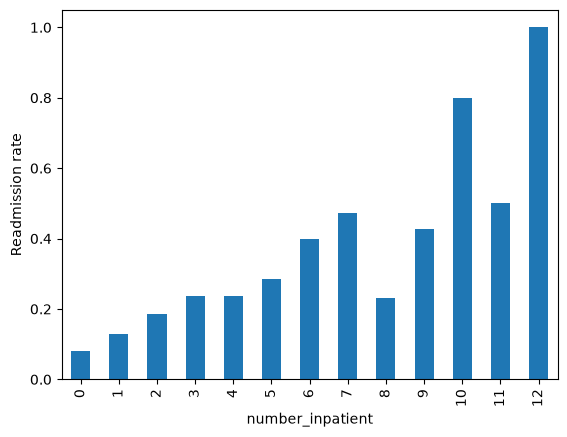

In [20]:
import matplotlib.pyplot as plt

df.groupby("number_inpatient")["target"].mean().plot(kind="bar")
plt.ylabel("Readmission rate")
plt.show()

In [21]:
df["number_inpatient"].value_counts().sort_index()

number_inpatient
0     61795
1      5798
2      1501
3       463
4       228
5       102
6        55
7        19
8        13
9         7
10        5
11        2
12        2
Name: count, dtype: int64

In [22]:
df.groupby("diag_group")["target"].mean().sort_values()

diag_group
Respiratory        0.073017
Digestive          0.080148
Musculoskeletal    0.083907
Genitourinary      0.089799
Other              0.089822
Neoplasms          0.090623
Diabetes           0.091162
Circulatory        0.096774
Injury             0.107964
Unknown            0.200000
Name: target, dtype: float64

In [23]:
df.groupby("discharge_disposition_id")["target"].mean().sort_values()

discharge_disposition_id
10    0.000000
16    0.000000
17    0.000000
27    0.000000
23    0.030769
24    0.040000
25    0.061697
1     0.069469
7     0.095355
6     0.095405
8     0.095890
18    0.101455
4     0.103321
3     0.134243
2     0.137573
5     0.205915
9     0.222222
22    0.263643
28    0.355556
15    0.450000
12    0.500000
Name: target, dtype: float64

In [24]:
df["discharge_disposition_id"].value_counts()

discharge_disposition_id
1     44322
3      8790
6      8291
18     2474
2      1541
22     1411
5       913
25      778
4       542
7       409
23      260
28       90
8        73
15       40
24       25
9         9
17        8
10        6
16        3
27        3
12        2
Name: count, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print("train positive rate:", y_train.mean())
print("test positive rate:", y_test.mean())

(55992, 24) (13998, 24)
Train positive rate: 0.08979854264894985
Test positive rate: 0.08979854264894985


In [27]:
numcols = X.select_dtypes(include=["number"]).columns
catcols = X.select_dtypes(exclude=["number"]).columns

print("numeric cols-", len(numcols))
print(list(numcols))
print("categorical cols-", len(catcols))
print(list(catcols))

numeric cols- 8
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
categorical cols- 16
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'metformin', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'change', 'diabetesMed', 'diag_group']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

num_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

cat_pipe = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)

preprocessor = ColumnTransformer([
    ("num", num_pipe, numcols),
    ("cat", cat_pipe, catcols),
], sparse_threshold=0)

In [29]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Before:", X_train.shape)
print("After: ", X_train_prepared.shape)

Before: (55992, 24)
After:  (55992, 114)


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
}
print(list(models.keys()))

['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN']


In [31]:
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

results = []
fitted = {}

for name, clf in models.items():
    pipe = make_pipeline(preprocessor, clf)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    p_train = pipe.predict_proba(X_train)[:, 1]
    p_test = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Train ROC-AUC": roc_auc_score(y_train, p_train),
        "Test ROC-AUC": roc_auc_score(y_test, p_test),
        "Test PR-AUC": average_precision_score(y_test, p_test),
    })
    print("done:", name)

results_df = pd.DataFrame(results).round(3).sort_values("Test ROC-AUC", ascending=False)
results_df

done: Logistic Regression
done: Decision Tree
done: Random Forest
done: KNN


,Model,Train ROC-AUC,Test ROC-AUC,Test PR-AUC
2,Random Forest,0.855,0.653,0.178
0,Logistic Regression,0.656,0.649,0.170
1,Decision Tree,0.656,0.624,0.154
3,KNN,0.740,0.570,0.111


In [32]:
import numpy as np

def capture_rate(y_true, scores, top_frac=0.2):
    n_top = int(len(scores) * top_frac)
    order = np.argsort(scores)[::-1]       # patient positions, highest risk first
    top_idx = order[:n_top]                # keep the top 20%
    return y_true.iloc[top_idx].sum() / y_true.sum()

for name, pipe in fitted.items():
    p = pipe.predict_proba(X_test)[:, 1]
    print(name, round(capture_rate(y_test, p), 3))

Logistic Regression 0.376
Decision Tree 0.365
Random Forest 0.384
KNN 0.27


In [33]:
final_model = fitted["Logistic Regression"]

feature_names = final_model.named_steps["columntransformer"].get_feature_names_out()
weights = final_model.named_steps["logisticregression"].coef_[0]

coef_df = pd.DataFrame({"feature": feature_names, "weight": weights})
coef_df = coef_df.sort_values("weight", ascending=False)

print(len(coef_df))
coef_df.head(10)

114


,feature,weight
37,cat__discharge_disposition_id_15,1.651631
47,cat__discharge_disposition_id_28,1.063224
42,cat__discharge_disposition_id_22,0.969973
50,cat__discharge_disposition_id_5,0.715810
65,cat__admission_source_id_3,0.657344
36,cat__discharge_disposition_id_12,0.565976
113,cat__diag_group_Unknown,0.552805
62,cat__admission_source_id_20,0.516804
31,cat__admission_type_id_6,0.382867
71,cat__admission_source_id_9,0.355229


In [34]:
coef_df.tail(10)

,feature,weight
35,cat__discharge_disposition_id_10,-0.412076
92,cat__rosiglitazone_Down,-0.430386
56,cat__admission_source_id_10,-0.447987
44,cat__discharge_disposition_id_24,-0.520279
34,cat__discharge_disposition_id_1,-0.567747
39,cat__discharge_disposition_id_17,-0.636354
16,cat__age_[0-10),-0.822950
32,cat__admission_type_id_7,-0.864175
45,cat__discharge_disposition_id_25,-0.872996
43,cat__discharge_disposition_id_23,-1.826850


In [35]:
coef_df[coef_df["feature"].str.startswith("num__")].sort_values("weight", ascending=False)

,feature,weight
6,num__number_inpatient,0.217341
5,num__number_emergency,0.078436
0,num__time_in_hospital,0.077681
7,num__number_diagnoses,0.066724
1,num__num_lab_procedures,0.005777
4,num__number_outpatient,0.001647
3,num__num_medications,-0.001305
2,num__num_procedures,-0.008283


In [36]:
for c in ["admission_source_id", "admission_type_id"]:
    print(X_train[c].value_counts(), "\n")

admission_source_id
7     29870
1     17377
17     3853
4      1995
6      1415
2       725
5       420
20      123
3       111
9        79
8         9
10        6
22        4
25        2
11        1
14        1
13        1
Name: count, dtype: int64 

admission_type_id
1    28439
3    10997
2    10261
6     3596
5     2463
8      218
7       12
4        6
Name: count, dtype: int64 



In [37]:
p_final = final_model.predict_proba(X_test)[:, 1]

for frac in [0.05, 0.10, 0.20, 0.30, 0.50]:
    caught = capture_rate(y_test, p_final, top_frac=frac)
    lift = caught / frac
    print(f"Flag top {int(frac*100):>2}% -> catch {caught:.1%} of readmissions (lift {lift:.2f}x)")

Flag top  5% -> catch 15.0% of readmissions (lift 3.01x)
Flag top 10% -> catch 23.6% of readmissions (lift 2.36x)
Flag top 20% -> catch 37.6% of readmissions (lift 1.88x)
Flag top 30% -> catch 48.4% of readmissions (lift 1.61x)
Flag top 50% -> catch 68.5% of readmissions (lift 1.37x)


In [ ]:
import joblib, os

BASE = "."                # the folder this notebook is in
MODELS_DIR = os.path.join(BASE, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

for name, pipe in fitted.items():
    filename = os.path.join(MODELS_DIR, name.lower().replace(" ", "_") + ".joblib")
    joblib.dump(pipe, filename)
    print("saved:", filename)

saved: D:\DS-DAA\proj2\models\logistic_regression.joblib
saved: D:\DS-DAA\proj2\models\decision_tree.joblib
saved: D:\DS-DAA\proj2\models\random_forest.joblib
saved: D:\DS-DAA\proj2\models\knn.joblib


In [39]:
import json

with open(os.path.join(MODELS_DIR, "feature_columns.json"), "w") as f:
    json.dump(list(X_train.columns), f)

scores = {name: pipe.predict_proba(X_test)[:, 1].tolist() for name, pipe in fitted.items()}
with open(os.path.join(MODELS_DIR, "test_scores.json"), "w") as f:
    json.dump(scores, f)

print("columns saved:", len(X_train.columns))

columns saved: 24


In [40]:
import sklearn
print("scikit-learn version:", sklearn.__version__)
print(sorted(os.listdir(MODELS_DIR)))

scikit-learn version: 1.8.0
['decision_tree.joblib', 'feature_columns.json', 'knn.joblib', 'logistic_regression.joblib', 'random_forest.joblib', 'test_scores.json']


In [41]:
for f in sorted(os.listdir(MODELS_DIR)):
    size_mb = os.path.getsize(os.path.join(MODELS_DIR, f)) / 1_000_000
    print(f"{f:30s} {size_mb:8.2f} MB")

decision_tree.joblib               0.02 MB
feature_columns.json               0.00 MB
knn.joblib                        16.81 MB
logistic_regression.joblib         0.01 MB
random_forest.joblib              27.41 MB
test_scores.json                   0.93 MB


In [42]:
options = {c: sorted(X_train[c].dropna().unique().tolist()) for c in catcols}

numeric_ranges = {
    c: {"min": int(X_train[c].min()),
        "max": int(X_train[c].max()),
        "median": float(X_train[c].median())}
    for c in numcols
}

with open(os.path.join(MODELS_DIR, "options.json"), "w") as f:
    json.dump({"categorical": options, "numeric": numeric_ranges}, f)

print(len(options), "categorical fields,", len(numeric_ranges), "numeric fields")
print(options["age"])

16 categorical fields, 8 numeric fields
['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']


In [43]:
import csv

sections = {}
current = None
with open(os.path.join(BASE, "IDS_mapping.csv"), newline="") as f:
    for row in csv.reader(f):
        if not row or not row[0].strip():
            continue                                  # skip the blank separator rows
        if row[0] in ("admission_type_id", "discharge_disposition_id", "admission_source_id"):
            current = row[0]                          # a header row starts a new table
            sections[current] = {}
        else:
            sections[current][row[0].strip()] = row[1].strip()

# any code in our data that has no label?
for col in sections:
    missing = [v for v in options[col] if v not in sections[col]]
    print(col, "-> unlabeled codes:", missing)

defaults = {c: X_train[c].mode()[0] for c in catcols}

with open(os.path.join(MODELS_DIR, "labels.json"), "w") as f:
    json.dump(sections, f)
with open(os.path.join(MODELS_DIR, "defaults.json"), "w") as f:
    json.dump(defaults, f)

print(sections["discharge_disposition_id"]["22"])

admission_type_id -> unlabeled codes: []
discharge_disposition_id -> unlabeled codes: []
admission_source_id -> unlabeled codes: []
Discharged/transferred to another rehab fac including rehab units of a hospital .
